In [1]:
import sys
# import ResNet_BN
import pickle
import matplotlib.pyplot as plt


sys.path.append('/content/sample_data')

In [2]:
# import ResNet_BN
# model = ResNet_BN.ResNet18(num_classes=10)
# # model.build(input_shape=(None, 32, 32, 3))
# # model.summary()

In [3]:
lr = [5e-3, 1e-3, 5e-4, 1e-4]

In [4]:
h_cutmix = [
    '/content/ConvMixer_10_CutMix_5e-03.pkl',
    '/content/ConvMixer_10_CutMix_1e-03.pkl',
    '/content/ConvMixer_10_CutMix_5e-04.pkl',
    '/content/ConvMixer_10_CutMix_1e-04.pkl'
]

histories_cutmix = {}
for i in range(len(lr)):
    with open(h_cutmix[i], 'rb') as f:
        history = pickle.load(f)
        histories_cutmix[lr[i]] = history

In [5]:
h = [
    '/content/ConvMixer_10_Normal_5e-03.pkl',
    '/content/ConvMixer_10_Normal_1e-03.pkl',
    '/content/ConvMixer_10_Normal_5e-04.pkl',
    '/content/ConvMixer_10_Normal_1e-04.pkl'
]

histories= {}
for i in range(len(lr)):
    with open(h[i], 'rb') as f:
        history = pickle.load(f)
        histories[lr[i]] = history

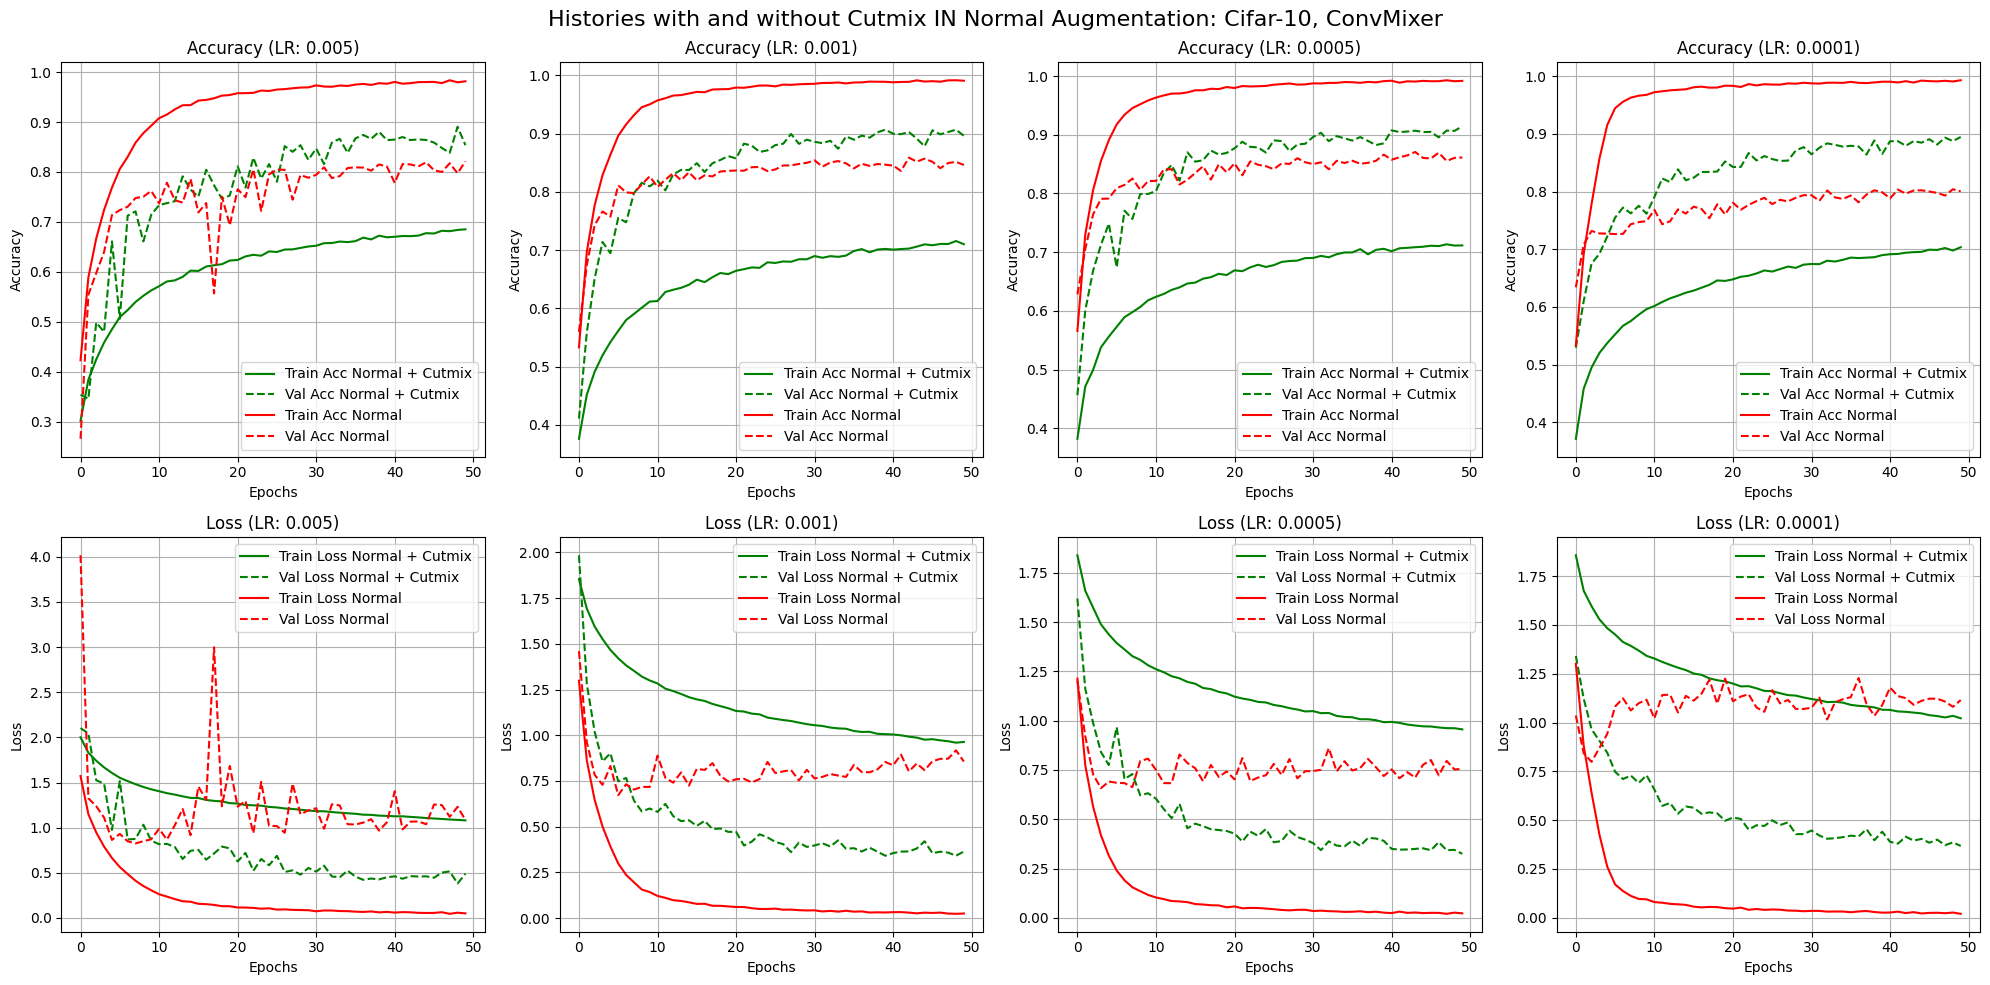

In [6]:
def plot_comparison_histories(histories_cutmix, histories):
    num_histories = len(histories_cutmix)

    fig, axes = plt.subplots(2, num_histories, figsize=(5 * num_histories, 10))

    for i, lr in enumerate(histories_cutmix.keys()):
        history_cutmix = histories_cutmix[lr]
        history = histories[lr]

        # Accuracy plots
        axes[0, i].plot(history_cutmix["accuracy"], label="Train Acc Normal + Cutmix", color='green')
        axes[0, i].plot(history_cutmix["val_accuracy"], label="Val Acc Normal + Cutmix", color='green', linestyle='--')
        axes[0, i].plot(history["accuracy"], label="Train Acc Normal", color='red')
        axes[0, i].plot(history["val_accuracy"], label="Val Acc Normal", color='red', linestyle='--')
        axes[0, i].set_title(f"Accuracy (LR: {lr})")
        axes[0, i].set_xlabel("Epochs")
        axes[0, i].set_ylabel("Accuracy")
        axes[0, i].legend()
        axes[0, i].grid()

        # Loss plots
        axes[1, i].plot(history_cutmix["loss"], label="Train Loss Normal + Cutmix", color='green')
        axes[1, i].plot(history_cutmix["val_loss"], label="Val Loss Normal + Cutmix", color='green', linestyle='--')
        axes[1, i].plot(history["loss"], label="Train Loss Normal", color='red')
        axes[1, i].plot(history["val_loss"], label="Val Loss Normal", color='red', linestyle='--')
        axes[1, i].set_title(f"Loss (LR: {lr})")
        axes[1, i].set_xlabel("Epochs")
        axes[1, i].set_ylabel("Loss")
        axes[1, i].legend()
        axes[1, i].grid()

    # Set a title for the entire subplot
    fig.suptitle("Histories with and without Cutmix IN Normal Augmentation: Cifar-10, ConvMixer", fontsize=16)

    plt.tight_layout()
    plt.show()

plot_comparison_histories(histories_cutmix, histories)


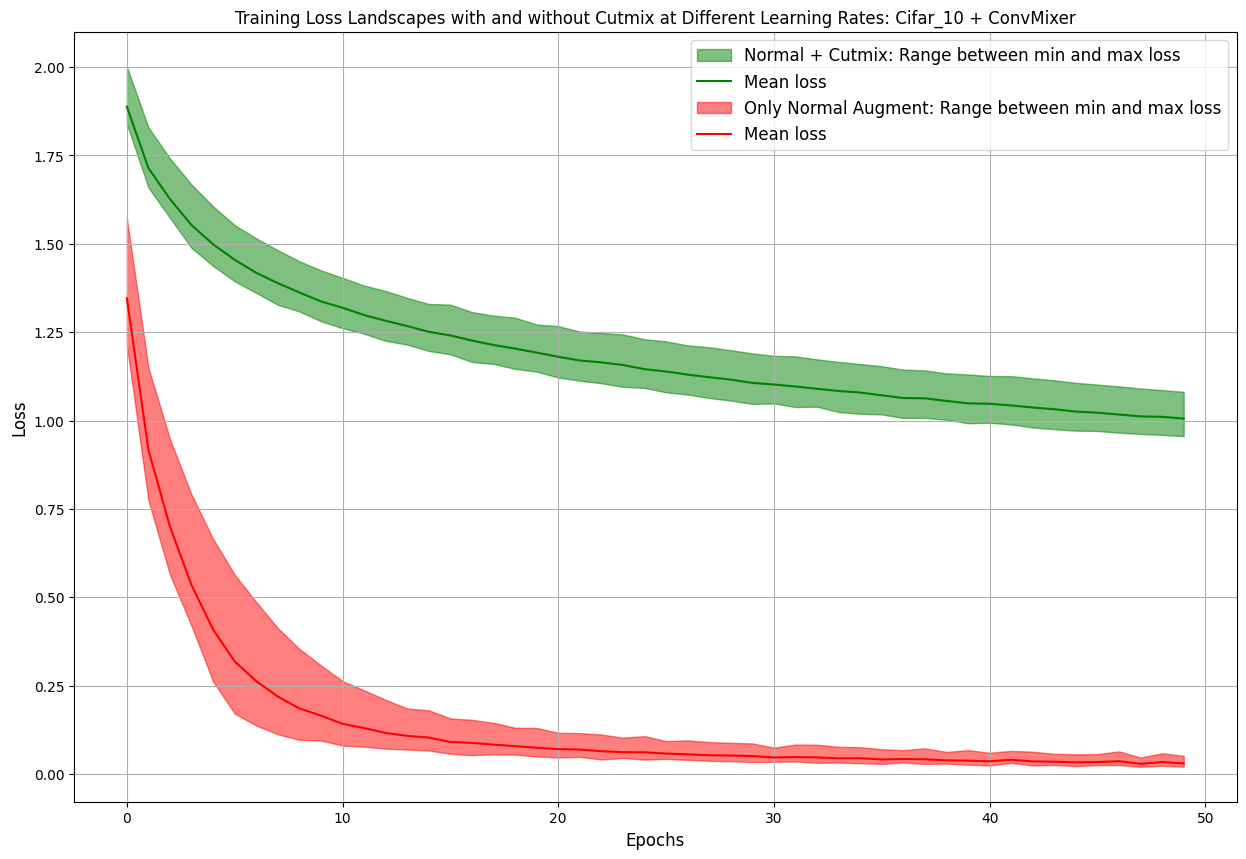

In [16]:
import numpy as np
import matplotlib.pyplot as plt

def plot_loss_landscapes(histories_bn, histories_no_bn):

    losses_bn = {lr: np.array(hist["loss"]) for lr, hist in histories_cutmix.items()}
    losses_no_bn = {lr: np.array(hist["loss"]) for lr, hist in histories.items()}


    min_length_bn = min(len(loss) for loss in losses_bn.values())
    min_length_no_bn = min(len(loss) for loss in losses_no_bn.values())
    min_length = min(min_length_bn, min_length_no_bn)


    min_curve_bn, max_curve_bn, mean_curve_bn = [], [], []
    min_curve_no_bn, max_curve_no_bn, mean_curve_no_bn = [], [], []


    for i in range(min_length):
        loss_values_at_epoch_bn = [loss[i] for loss in losses_bn.values()]
        min_curve_bn.append(np.min(loss_values_at_epoch_bn))
        max_curve_bn.append(np.max(loss_values_at_epoch_bn))
        mean_curve_bn.append(np.mean(loss_values_at_epoch_bn))


    for i in range(min_length):
        loss_values_at_epoch_no_bn = [loss[i] for loss in losses_no_bn.values()]
        min_curve_no_bn.append(np.min(loss_values_at_epoch_no_bn))
        max_curve_no_bn.append(np.max(loss_values_at_epoch_no_bn))
        mean_curve_no_bn.append(np.mean(loss_values_at_epoch_no_bn))

    plt.figure(figsize=(15, 10))


    plt.fill_between(range(min_length), min_curve_bn, max_curve_bn, color='green', alpha=0.5, label='Normal + Cutmix: Range between min and max loss')

    plt.plot(mean_curve_bn, color='green', linestyle='-', label='Mean loss')

    plt.fill_between(range(min_length), min_curve_no_bn, max_curve_no_bn, color='red', alpha=0.5, label='Only Normal Augment: Range between min and max loss')
    plt.plot(mean_curve_no_bn, color='red', linestyle='-', label='Mean loss')

    plt.xlabel('Epochs', fontsize=12)
    plt.ylabel('Loss', fontsize=12)
    plt.title('Training Loss Landscapes with and without Cutmix at Different Learning Rates: Cifar_10 + ConvMixer')
    plt.legend(loc='best', fontsize=12)
    # plt.show()
    # plt.legend()
    plt.grid(True)
    plt.show()

plot_loss_landscapes(histories_cutmix, histories)


In [8]:
import numpy as np
import matplotlib.pyplot as plt

#############################       with Batch norm #############################################

losses_bn = {lr: np.array(hist["loss"]) for lr, hist in histories_bn.items()}


min_length_bn = min(len(loss) for loss in losses_bn.values())


min_curve_bn = []
max_curve_bn = []
mean_curve_bn = []


for i in range(min_length_bn):
    loss_values_at_epoch_bn = [loss[i] for loss in losses_bn.values()]
    min_curve_bn.append(np.min(loss_values_at_epoch_bn))
    max_curve_bn.append(np.max(loss_values_at_epoch_bn))
    mean_curve_bn.append(np.mean(loss_values_at_epoch_bn))

plt.figure(figsize=(15, 10))

for lr, loss in losses_bn.items():
    plt.plot(loss[:min_length_bn], label=f'LR {lr}', linestyle='--')


plt.fill_between(range(min_length_bn), min_curve_bn, max_curve_bn, color='green', alpha=0.5, label='Range between min and max loss')


plt.plot(mean_curve_bn, color='black', label='Mean loss')

plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('Training Loss over Epochs with BatchNorm at Different Learning Rates for ResNet')
plt.legend()
plt.grid(True)
plt.show()

############################################ without batch norm ######################################################


losses_no_bn = {lr: np.array(hist["loss"]) for lr, hist in histories_no_bn.items()}


min_length_no_bn = min(len(loss) for loss in losses_no_bn.values())


min_curve_no_bn = []
max_curve_no_bn = []
mean_curve_no_bn = []


for i in range(min_length_no_bn):
    loss_values_at_epoch_no_bn = [loss[i] for loss in losses_no_bn.values()]
    min_curve_no_bn.append(np.min(loss_values_at_epoch_no_bn))
    max_curve_no_bn.append(np.max(loss_values_at_epoch_no_bn))
    mean_curve_no_bn.append(np.mean(loss_values_at_epoch_no_bn))

plt.figure(figsize=(15, 10))


for lr, loss in losses_no_bn.items():
    plt.plot(loss[:min_length_no_bn], label=f'LR {lr}', linestyle='--')


plt.fill_between(range(min_length_no_bn), min_curve_no_bn, max_curve_no_bn, color='red', alpha=0.5, label='Range between min and max loss')


plt.plot(mean_curve_no_bn, color='black', label='Mean loss')


plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('Training Loss over Epochs without BatchNorm at Different Learning Rates for ResNet')
plt.legend()
plt.grid(True)


plt.show()


NameError: name 'histories_bn' is not defined